# Анализ причин отсутствия увеличения выручки маркетплейса

Несколько месяцев выручка маркетплейса стоит на месте. Нужно разобраться, с чем это может быть связано и на каких изменениях стоит сконцентрироваться.

**Задача:** исследовать поведение покупателей, найти возможные точки роста и выбрать гипотезу для проверки.

**План исследования:**
1. Оценить месячный retention в **оформление заказа** с помощью когортного анализа.
2. Определить, существует ли product/market fit у этого маркетплейса.
3. Определить 5 основных метрик, на которых продакту можно сконцентрироваться, чтобы максимизировать прибыль компании.
4. Выбрать одну из 3 основных гипотез с помощью фреймворка ICE.
5. Сформулировать нужные метрики, на которые гипотеза должна повлиять.
6. Сделать выводы.

Для анализа есть три таблицы: заказы, покупатели и товары в заказах.
Начнём с исследования данных, затем перейдём к retention и остальным метрикам.


<div style="background-color: #e8f4f8; color: #183153; padding: 16px;">
    <b>Импорт библиотек</b>
</div>


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.ticker import PercentFormatter
import seaborn as sns

sns.set_style('whitegrid')


## Задача 1. Оценить месячный retention в оформление заказа

В ходе выполнения задачи нужно:

1. Исследовать данные и определить, какие заказы будем учитывать.
2. Построить месячный retention с помощью когортного анализа.
3. Посчитать медианный retention первого месяца по всем наблюдаемым когортам.
4. Найти когорту с самым высоким retention на третий месяц.
5. Показать результаты на тепловой карте.

### 1. Исследование данных

#### 1.1. Таблица orders

В таблице собрана информация о заказах и этапах их выполнения.

- `order_id` — уникальный идентификатор заказа.
- `customer_id` — позаказный идентификатор покупателя.
- `order_status` — статус заказа.
- `order_purchase_timestamp` — время создания заказа.
- `order_approved_at` — время подтверждения оплаты.
- `order_delivered_carrier_date` — время передачи заказа в логистическую службу.
- `order_delivered_customer_date` — время доставки покупателю.
- `order_estimated_delivery_date` — обещанная дата доставки.

Статусы заказов:

- `created` — создан;
- `approved` — подтверждён;
- `invoiced` — выставлен счёт;
- `processing` — в процессе сборки;
- `shipped` — передан в доставку;
- `delivered` — доставлен покупателю;
- `unavailable` — недоступен для выполнения;
- `canceled` — отменён.


In [2]:
date_columns = ['order_purchase_timestamp', 'order_approved_at',
                'order_delivered_carrier_date', 'order_delivered_customer_date',
                'order_estimated_delivery_date']
orders = pd.read_csv('olist_orders_dataset.csv', parse_dates=date_columns)
print('Размер таблицы:', orders.shape)
display(orders.head())


Размер таблицы: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


Посмотрим на типы данных, пропуски и дубликаты. Даты сразу преобразовали в `datetime`.


In [3]:
orders.info()
display(orders.isna().sum().rename('Пропуски').to_frame())
print('Дубликаты order_id:', orders['order_id'].duplicated().sum())
assert orders['order_id'].notna().all() and orders['order_id'].is_unique
assert orders['order_purchase_timestamp'].notna().all()


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB
Дубликаты order_id: 0


,Пропуски
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


У всех **99,441** заказов есть идентификатор, статус и дата создания. По этим полям можно считать оформления.

- У **160** заказов нет даты подтверждения оплаты.
- У **1783** — даты передачи перевозчику.
- У **2965** — даты доставки.

Посмотрим, с какими статусами связаны эти пропуски.


In [4]:
status_summary = orders.groupby('order_status').agg(orders=('order_id', 'nunique'))
status_summary['share'] = status_summary['orders'] / len(orders)
status_summary['share_percent'] = (status_summary.pop('share') * 100).round(2)
display(status_summary)
display(pd.crosstab(orders['order_status'], orders['order_approved_at'].notna(),
                    colnames=['Есть дата подтверждения оплаты']))


,orders,share_percent
order_status,,
approved,2,0.00
canceled,625,0.63
created,5,0.01
delivered,96478,97.02
invoiced,314,0.32
processing,301,0.30
shipped,1107,1.11
unavailable,609,0.61


Есть дата подтверждения оплаты,False,True
order_status,,
approved,0,2
canceled,141,484
created,5,0
delivered,14,96464
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


Видим, что около **97% заказов доставлены**. По каждому `order_id` есть одна строка,
поэтому будем рассматривать статус как последний известный на момент выгрузки.

Среди заказов без даты подтверждения оплаты есть доставленные. Есть и обратная
ситуация: дата подтверждения заполнена, а статус остался `invoiced`.
Причины таких сочетаний по этим таблицам не видны. Для расчёта оформления это
не мешает: дата создания есть у всех заказов.


#### 1.2. Таблица customers

Теперь посмотрим на покупателей.

- `customer_id` — позаказный идентификатор покупателя.
- `customer_unique_id` — идентификатор одного и того же покупателя в разных заказах.
- `customer_zip_code_prefix` — почтовый индекс.
- `customer_city` — город доставки.
- `customer_state` — штат доставки.


In [5]:
customers = pd.read_csv('olist_customers_dataset.csv')
print('Размер таблицы:', customers.shape)
display(customers.head())
display(customers.isna().sum().rename('Пропуски').to_frame())
print('Дубликаты customer_id:', customers['customer_id'].duplicated().sum())
print('Уникальные customer_id:', customers['customer_id'].nunique())
print('Уникальные customer_unique_id:', customers['customer_unique_id'].nunique())
assert customers['customer_id'].notna().all() and customers['customer_id'].is_unique
assert customers['customer_unique_id'].notna().all()
display(customers.groupby('customer_unique_id').agg(orders=('customer_id', 'nunique'))
        .sort_values('orders', ascending=False).head())


Размер таблицы: (99441, 5)
Дубликаты customer_id: 0
Уникальные customer_id: 99441
Уникальные customer_unique_id: 96096


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


,Пропуски
customer_id,0
customer_unique_id,0
customer_zip_code_prefix,0
customer_city,0
customer_state,0


,orders
customer_unique_id,
8d50f5eadf50201ccdcedfb9e2ac8455,17
3e43e6105506432c953e165fb2acf44c,9
6469f99c1f9dfae7733b25662e7f1782,7
ca77025e7201e3b30c44b472ff346268,7
1b6c7548a2a1f9037c1fd3ddfed95f33,7


Пропусков и дубликатов по `customer_id` нет. При этом одному `customer_unique_id`
может соответствовать несколько `customer_id`.

Значит, чтобы увидеть повторный заказ одного человека, нужно использовать
**`customer_unique_id`**. Разные позаказные идентификаторы не означают разные аккаунты.


#### 1.3. Таблица items

В этой таблице перечислены товары, входящие в каждый заказ.

- `order_id` — идентификатор заказа.
- `order_item_id` — номер товарной позиции внутри заказа.
- `product_id` — идентификатор товара.
- `seller_id` — идентификатор продавца.
- `shipping_limit_date` — крайний срок передачи товара в логистическую службу.
- `price` — стоимость товарной позиции.
- `freight_value` — стоимость доставки позиции.

Один заказ может занимать несколько строк. Для среднего чека позже сначала
сложим стоимость всех его позиций.


In [6]:
items = pd.read_csv('olist_order_items_dataset.csv', parse_dates=['shipping_limit_date'])
print('Размер таблицы:', items.shape)
display(items.head())
display(items.isna().sum().rename('Пропуски').to_frame())
print('Дубликаты товарных позиций:', items.duplicated(['order_id', 'order_item_id']).sum())
assert not items.duplicated(['order_id', 'order_item_id']).any()
assert items['order_id'].isin(orders['order_id']).all()
assert items[['price', 'freight_value']].notna().all().all()
assert items[['price', 'freight_value']].ge(0).all().all()


Размер таблицы: (112650, 7)
Дубликаты товарных позиций: 0


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,Пропуски
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


#### 1.4. Объединение таблиц

Для retention нужно добавить к каждому заказу `customer_unique_id`.
Объединим `orders` и `customers` по полю `customer_id` и проверим, что количество
заказов осталось прежним и для всех нашёлся покупатель.


In [7]:
events_all = orders.merge(customers, on='customer_id', how='left',
                          validate='many_to_one', indicator=True)
assert events_all['_merge'].eq('both').all()
events_all = events_all.drop(columns='_merge')
events_all['order_month'] = events_all['order_purchase_timestamp'].dt.to_period('M')
assert len(events_all) == len(orders)


print('Заказов до объединения:', len(orders))
print('Заказов после объединения:', len(events_all))
print('Без customer_unique_id:', events_all['customer_unique_id'].isna().sum())


Заказов до объединения: 99441
Заказов после объединения: 99441
Без customer_unique_id: 0


Теперь проверим, для всех ли заказов есть товарные позиции в `items`.


In [8]:
missing_items = events_all.loc[~events_all['order_id'].isin(items['order_id'])]
print('Заказов без товарных позиций:', len(missing_items))
display(missing_items.groupby('order_status').size().rename('Заказы').to_frame())


Заказов без товарных позиций: 775


,Заказы
order_status,
canceled,164
created,5
invoiced,2
shipped,1
unavailable,603


В `orders` на **775 заказов** больше, чем в `items`. В основном это заказы
со статусами `unavailable` и `canceled`.

Для retention оставим их в данных: факт оформления зарегистрирован в `orders`.
При расчёте стоимости будем использовать заказы, для которых есть товарные позиции.


#### 1.5. Период исследования

Посмотрим, какие даты охватывает выгрузка и как заказы распределяются по месяцам.


In [9]:
print('Первый заказ:', orders['order_purchase_timestamp'].min())
print('Последний заказ:', orders['order_purchase_timestamp'].max())


Первый заказ: 2016-09-04 21:15:19
Последний заказ: 2018-10-17 17:30:18


order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable,total
2016-09,0,2,0,1,0,0,1,0,4
2016-10,0,24,0,265,18,2,8,7,324
2016-11,0,0,0,0,0,0,0,0,0
2016-12,0,0,0,1,0,0,0,0,1
2017-01,0,3,0,750,12,9,16,10,800
2017-02,1,17,0,1653,11,32,21,45,1780
2017-03,0,33,0,2546,3,23,45,32,2682
2017-04,1,18,0,2303,14,10,49,9,2404
2017-05,0,29,0,3546,16,23,55,31,3700
2017-06,0,16,0,3135,11,12,47,24,3245


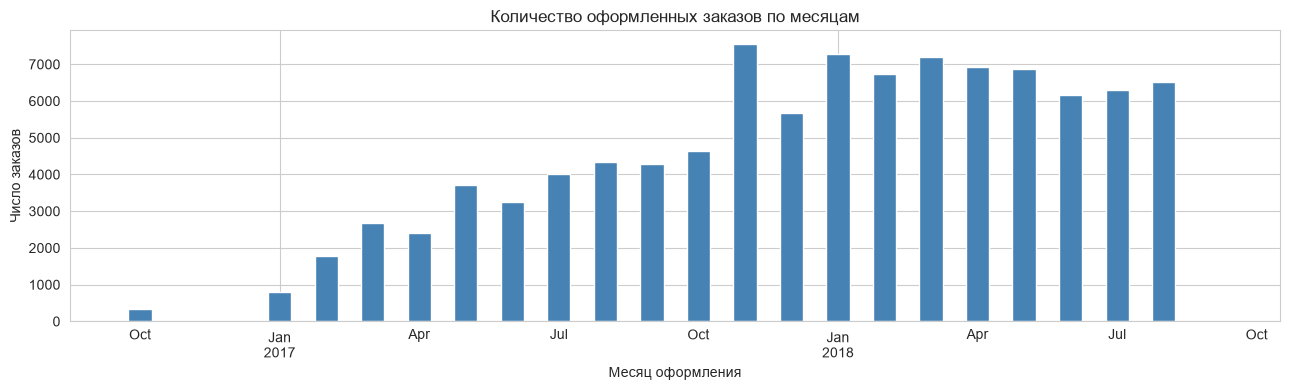

In [10]:
coverage = pd.crosstab(events_all['order_month'], events_all['order_status'])
coverage = coverage.reindex(pd.period_range(events_all['order_month'].min(),
                                           events_all['order_month'].max(), freq='M'), fill_value=0)
coverage['total'] = coverage.sum(axis=1)
display(coverage)
ax = coverage['total'].plot.bar(figsize=(13, 4), color='steelblue')
ax.set(xlabel='Месяц оформления', ylabel='Число заказов', title='Количество оформленных заказов по месяцам')
plt.tight_layout()
plt.show()


За сентябрь 2018 года есть только **16 заказов**, за октябрь — **4**.
Это сильно отличается от предыдущих месяцев. Возможно, данные за конец периода
выгружены не полностью.

Для основных расчётов остановимся на **августе 2018 года**, считая его последним
полным месяцем. Это предположение нужно подтвердить у владельца данных.

За 2016 год заказов тоже мало. Пока оставим их: иначе пользователь с первым заказом
в 2016 году может ошибочно попасть в новую когорту в 2017-м.
Первым заказом будем называть первый заказ, который видим в этой выгрузке.


In [11]:
end_month = pd.Period('2018-08', freq='M')

events = events_all.loc[events_all['order_month'] <= end_month].copy()
excluded_tail = events_all.loc[events_all['order_month'] > end_month]
print('Заказов в основном периоде:', len(events))
print('Заказов после августа 2018:', len(excluded_tail))


Заказов в основном периоде: 99421
Заказов после августа 2018: 20


#### 1.6. Какие заказы будем учитывать в retention

В задаче нужно оценить возвращение **к оформлению заказа**. Поэтому будем считать
событием создание заказа по `order_purchase_timestamp` и учитывать все статусы.

Если заказ позже отменили или не смогли доставить, само оформление уже произошло.
Оплата и доставка — следующие этапы. Для них можно отдельно посчитать свои метрики.

Подводя итог:

- для retention используем все оформленные заказы;
- покупателя определяем по `customer_unique_id`;
- датой события считаем `order_purchase_timestamp`;
- для объёма продаж и среднего чека используем доставленные заказы.

### 2. Построение месячного retention

Для каждого пользователя найдём месяц первого заказа — это его когорта.
Затем посчитаем, какая доля покупателей из этой когорты оформляла заказы
в каждый следующий календарный месяц.

Месяц первого заказа обозначим **M0**, следующий месяц — **M1**, через три месяца — **M3**.
Например, первый заказ в январе и следующий в феврале дают возвращение в M1,
даже если между ними прошло меньше 30 дней. Внутри месяца считаем пользователя один раз.

Важно различать два случая:

- месяц уже прошёл, но никто не вернулся — retention равен **0**;
- месяц ещё не наступил к концу нашего периода — оставляем **NaN**.

Размер когорты всегда берём из M0. Пользователь может пропустить один месяц
и вернуться позже — в соответствующем месяце мы его учтём.


In [12]:
# Для каждого заказа найдём месяц оформления и месяц первого заказа покупателя.
data = events[['customer_unique_id', 'order_purchase_timestamp']].copy()
data['month'] = data['order_purchase_timestamp'].dt.to_period('M')
data['cohort'] = data.groupby('customer_unique_id')['month'].transform('min')
data['age'] = data['month'].astype('int64') - data['cohort'].astype('int64')

data.head()


Out[12]: 
                 customer_unique_id order_purchase_timestamp  ...   cohort  age
0  7c396fd4830fd04220f754e42b4e5bff      2017-10-02 10:56:33  ...  2017-09    1
1  af07308b275d755c9edb36a90c618231      2018-07-24 20:41:37  ...  2018-07    0
2  3a653a41f6f9fc3d2a113cf8398680e8      2018-08-08 08:38:49  ...  2018-08    0
3  7c142cf63193a1473d2e66489a9ae977      2017-11-18 19:28:06  ...  2017-11    0
4  72632f0f9dd73dfee390c9b22eb56dd6      2018-02-13 21:18:39  ...  2018-02    0

[5 rows x 5 columns]


In [13]:
# Считаем уникальных покупателей в каждой когорте и месяце.
data_cohort = data.groupby(['cohort', 'age']).agg(
    n_customers=('customer_unique_id', 'nunique')).reset_index()

cohort_pivot = data_cohort.pivot(index='cohort', columns='age', values='n_customers')

# Добавляем все месяцы, в том числе те, в которых никто не вернулся.
last_period = (end_month - data['cohort'].min()).n
cohort_pivot = cohort_pivot.reindex(columns=range(last_period + 1)).fillna(0)

# Месяцы, которые ещё не наблюдались, оставляем пустыми.
for cohort in cohort_pivot.index:
    observed_months = (end_month - cohort).n
    cohort_pivot.loc[cohort, cohort_pivot.columns > observed_months] = np.nan

cohort_size = cohort_pivot[0]
retention = cohort_pivot.divide(cohort_size, axis=0)
cohort_counts = cohort_pivot
cohort_events = data

# Значения таблицы — в процентах.
(retention.iloc[:, :7] * 100).round(2)


Out[13]: 
age          0       1     2     3     4     5     6
cohort                                              
2016-09  100.0    0.00  0.00  0.00  0.00  0.00  0.00
2016-10  100.0    0.00  0.00  0.00  0.00  0.00  0.31
2016-12  100.0  100.00  0.00  0.00  0.00  0.00  0.00
2017-01  100.0    0.39  0.26  0.13  0.39  0.13  0.52
2017-02  100.0    0.23  0.29  0.11  0.40  0.11  0.23
2017-03  100.0    0.49  0.38  0.38  0.34  0.15  0.15
2017-04  100.0    0.60  0.21  0.17  0.34  0.26  0.34
2017-05  100.0    0.50  0.50  0.39  0.31  0.33  0.42
2017-06  100.0    0.48  0.35  0.41  0.25  0.38  0.38
2017-07  100.0    0.51  0.36  0.26  0.28  0.21  0.31
2017-08  100.0    0.69  0.33  0.26  0.36  0.53  0.29
2017-09  100.0    0.68  0.53  0.29  0.46  0.22  0.22
2017-10  100.0    0.69  0.25  0.09  0.22  0.20  0.22
2017-11  100.0    0.55  0.38  0.18  0.19  0.18  0.11
2017-12  100.0    0.26  0.27  0.35  0.27  0.20  0.16
2018-01  100.0    0.34  0.38  0.28  0.28  0.16  0.17
2018-02  100.0    0.39  0.39  0.29  

In [14]:
median_m1 = retention[1].median()
best_m3 = retention[3].idxmax()
best_m3_value = retention[3].max()

print(f'Медианный retention M1: {median_m1:.3%}')
print(f'Максимальный M3: {best_m3}, {best_m3_value:.3%}')


Медианный retention M1: 0.497%
Максимальный M3: 2017-06, 0.414%


### 3. Медианный retention первого месяца и лучшая когорта на M3

Возьмём M1 всех когорт, для которых следующий месяц уже наблюдался, и посчитаем медиану.
Для M3 найдём максимальное значение и посмотрим, сколько покупателей за ним стоит.


Медианный retention первого месяца по **22 когортам** составляет **0.497%**.

Самый высокий retention на третий месяц — у когорты **2017-06**: **0.414%**. Вернулись **13** из **3139** покупателей.


### 4. Тепловая карта

Покажем retention на тепловой карте. Слева оставим размеры когорт,
а M0 со значением 100% уберём из цветной части.


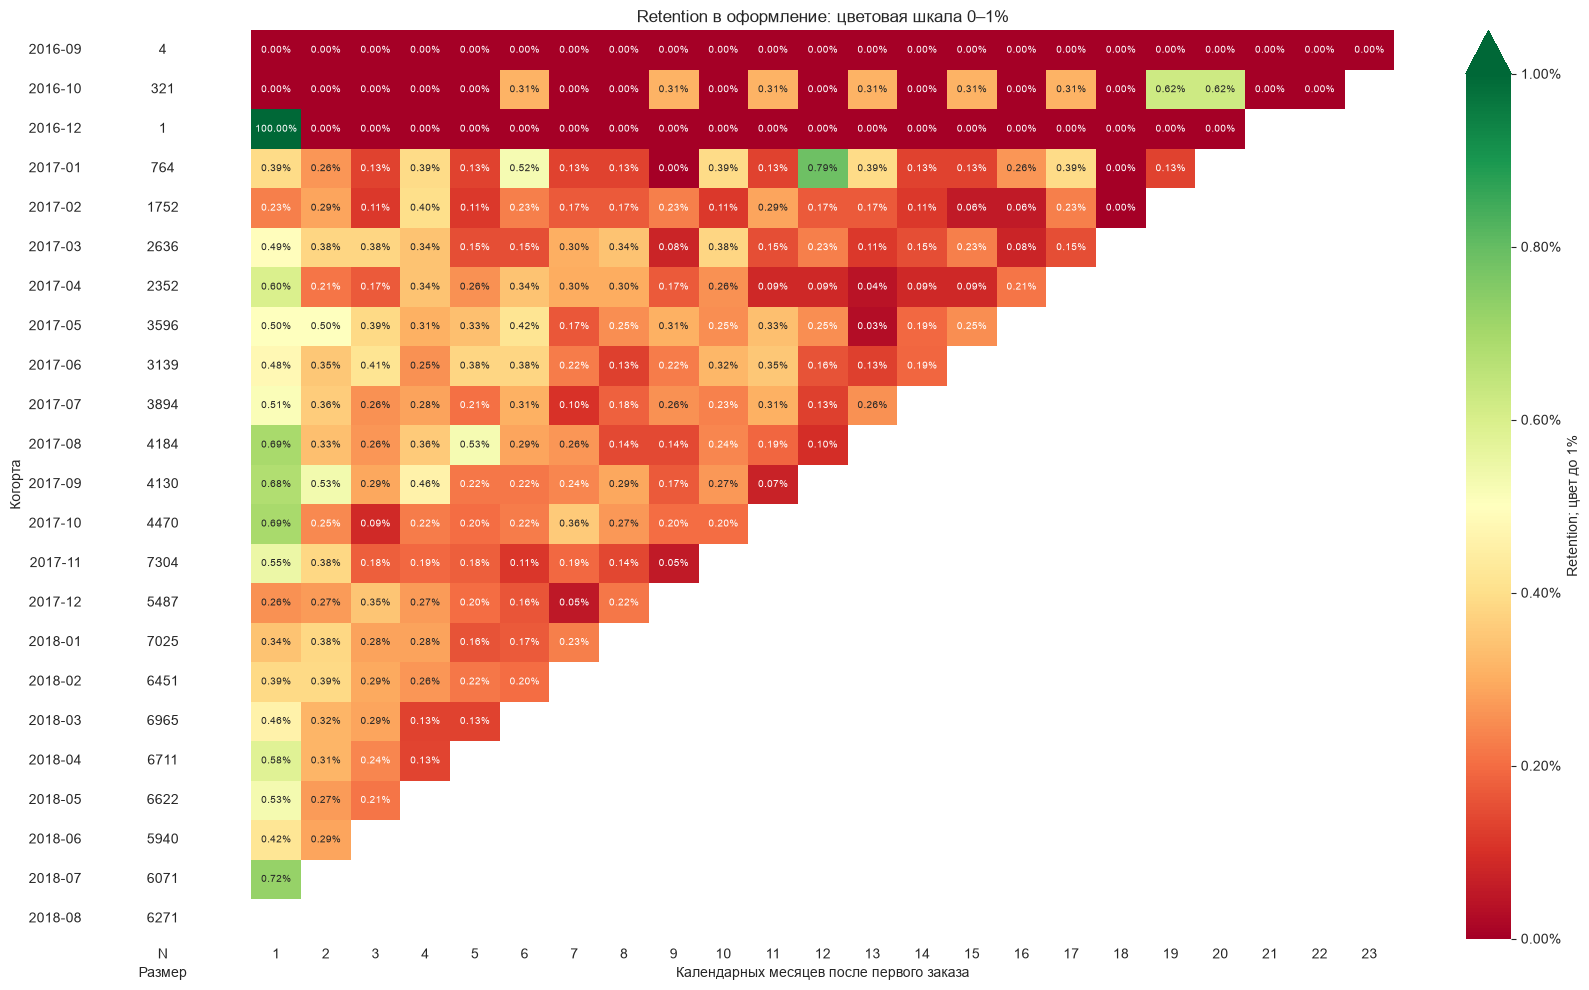

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(17, 10), sharey=True,
                         gridspec_kw={'width_ratios': [1.2, 12]})
sns.heatmap(cohort_size.to_frame('N'), annot=True, fmt='g', cbar=False,
            cmap=mcolors.ListedColormap(['white']), ax=axes[0])
axes[0].set(xlabel='Размер', ylabel='Когорта')
sns.heatmap(retention.drop(columns=0), mask=retention.drop(columns=0).isna(),
            annot=True, fmt='.2%', cmap='RdYlGn', vmin=0, vmax=0.01,
            annot_kws={'fontsize': 7}, ax=axes[1],
            cbar_kws={'format': PercentFormatter(1), 'extend': 'max', 'label': 'Retention; цвет до 1%'})
axes[1].set(xlabel='Календарных месяцев после первого заказа', ylabel='',
            title='Retention в оформление: цветовая шкала 0–1%')
axes[0].grid(False)
axes[1].grid(False)
plt.tight_layout()
plt.show()


Видим, что в большинстве когорт на следующий месяц возвращается меньше 1% покупателей.
Для сравнения этих небольших значений цветовая шкала ограничена 1%,
а подписи показывают фактический retention.

У декабря 2016 года M1 равен 100%, но в этой когорте всего **один покупатель**.
На таком размере даже один повторный заказ сильно меняет показатель.
Пустые ячейки относятся к месяцам, которые ещё не наблюдались; 0,00% — к месяцам без возвращений.


## Задача 2. Оценить product/market fit маркетплейса

Посмотрим, как меняется retention в течение нескольких месяцев после первого заказа.
Для этого возьмём одни и те же когорты с января 2017 года, у которых уже прошёл M6.
Так сравнение не будет зависеть от того, что на дальних месяцах остаются только старые когорты.

На графике покажем медиану по когортам.
Ещё посчитаем, сколько покупателей вернулись хотя бы раз в M1–M6.


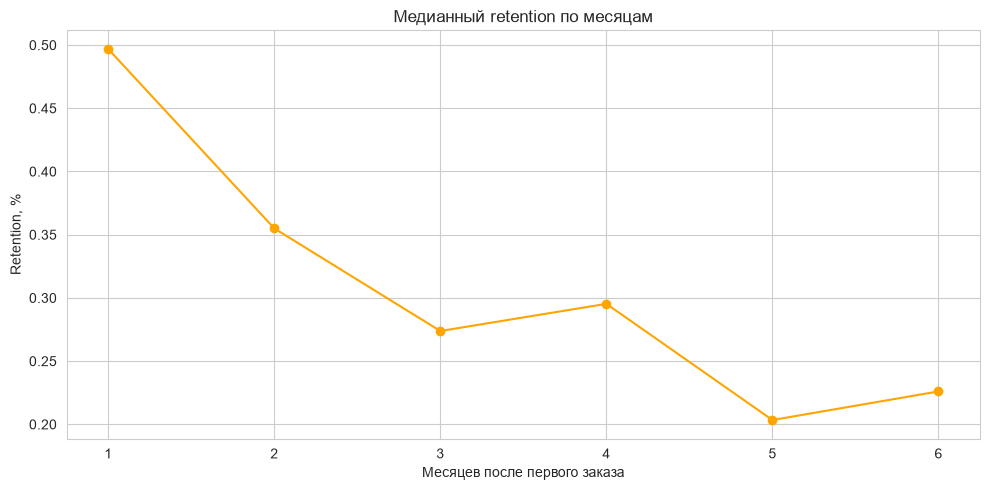

In [16]:
# Сравниваем одни и те же когорты, у которых уже прошёл шестой месяц.
common_index = retention.index[(retention.index >= '2017-01') & retention[6].notna()]
common = retention.loc[common_index, 1:6]
monthly_median = common.median()

plt.figure(figsize=(10, 5))
plt.plot(monthly_median.index, monthly_median * 100, marker='o', color='orange')
plt.title('Медианный retention по месяцам')
plt.xlabel('Месяцев после первого заказа')
plt.ylabel('Retention, %')
plt.tight_layout()
plt.show()

# Покупателей с возвращением хотя бы в одном из M1–M6 считаем один раз.
cumulative_users = (data.loc[data['cohort'].isin(common_index) & data['age'].between(1, 6)]
                    .groupby('cohort')['customer_unique_id'].nunique()
                    .reindex(common_index, fill_value=0))
cumulative_6 = cumulative_users / cohort_size.loc[common_index]
order_frequency = events.groupby('customer_unique_id')['order_id'].nunique()
single_share = order_frequency.eq(1).mean()


За доступный период **96.89%** пользователей оформили только один заказ. У новых покупателей было меньше времени на повторную покупку, поэтому считать всех этих пользователей окончательно ушедшими пока нельзя.

Если взять **14 когорт** с одинаковым горизонтом наблюдения, медианная доля вернувшихся хотя бы раз в течение M1–M6 составляет **1.79%**. Повторные заказы в месяц первой покупки в этот показатель не входят.


### Выводы по удержанию

Повторных оформлений мало. Это возможная точка роста: значительная часть покупателей
за доступное нам время ограничилась одним заказом.

При этом для уверенного вывода о PMF хотелось бы понимать, что именно продаёт
маркетплейс. Если это товары длительного пользования, ожидать ежемесячных покупок
может быть неправильно. Для таких категорий стоит смотреть на более длинные интервалы.

**По имеющимся данным устойчивый PMF подтвердить не можем.** В первую очередь стоит
разобраться с причинами низкой повторяемости: изучить категории товаров, каналы
привлечения и обратную связь после первого заказа.

Посмотрим также на доставку. Возможно, у покупателей есть сложности на этом этапе.

### 2.1. Время выполнения заказа

Разделим путь заказа на этапы:

- создание → подтверждение оплаты;
- подтверждение оплаты → передача перевозчику;
- передача перевозчику → доставка;
- создание → доставка.

Считаем длительность в сутках для доставленных заказов. Если одной из дат нет,
интервал остаётся пустым. Отрицательные значения отдельно посчитаем и исключим
из статистики соответствующего этапа.


In [17]:
delivered = events.loc[events['order_status'].eq('delivered')].copy()
stage_pairs = {
    'Оформление → подтверждение': ('order_purchase_timestamp', 'order_approved_at'),
    'Подтверждение → перевозчик': ('order_approved_at', 'order_delivered_carrier_date'),
    'Перевозчик → доставка': ('order_delivered_carrier_date', 'order_delivered_customer_date'),
    'Оформление → доставка': ('order_purchase_timestamp', 'order_delivered_customer_date'),
}
delivery_rows = []
for label, (start, finish) in stage_pairs.items():
    interval = (delivered[finish] - delivered[start]).dt.total_seconds() / 86400
    valid = interval.loc[interval.ge(0)]
    delivery_rows.append({'stage': label, 'valid_n': len(valid), 'missing_n': interval.isna().sum(),
        'negative_n': interval.lt(0).sum(), 'mean_days': valid.mean(), 'median_days': valid.median(),
        'p75_days': valid.quantile(0.75), 'p90_days': valid.quantile(0.9)})
delivery_summary = pd.DataFrame(delivery_rows).set_index('stage')
display(delivery_summary.round(2))


,valid_n,missing_n,negative_n,mean_days,median_days,p75_days,p90_days
stage,,,,,,,
Оформление → подтверждение,96464,14,0,0.43,0.01,0.60,1.44
Подтверждение → перевозчик,95112,16,1350,2.85,1.85,3.62,6.02
Перевозчик → доставка,96446,9,23,9.33,7.10,12.03,18.90
Оформление → доставка,96470,8,0,12.56,10.22,15.72,23.10


По медиане этапы занимают:

- оформление → подтверждение: **0.01 суток**.
- подтверждение → перевозчик: **1.85 суток**.
- перевозчик → доставка: **7.10 суток**.
- оформление → доставка: **10.22 суток**.

Встречаются заказы с нарушенным порядком дат. Причины стоит уточнить в системе учёта: по выгрузке определить их не получится.


### 2.2. Сравнение с обещанной датой доставки

Посмотрим, как часто заказ приходит позже обещанного срока.
Будем сравнивать календарные даты: доставка в течение обещанного дня считается своевременной.


In [18]:
delivered['delivery_days'] = (delivered['order_delivered_customer_date'] -
                              delivered['order_purchase_timestamp']).dt.total_seconds() / 86400
delivered['promise_delta_days'] = (delivered['order_delivered_customer_date'].dt.normalize() -
                                   delivered['order_estimated_delivery_date'].dt.normalize()).dt.days
known_delivery = delivered.loc[delivered['promise_delta_days'].notna()]
late_share = known_delivery['promise_delta_days'].gt(0).mean()


Из **96,470** доставленных заказов с известными датами опоздали **6.77%**. У **8** доставленных заказов даты для сравнения отсутствуют.


### 2.3. Доставка по штатам

Теперь посмотрим, различается ли время доставки в зависимости от штата покупателя.
Рядом с медианой выведем количество заказов и 90-й перцентиль.


,orders,median_days,p90_days
customer_state,,,
AM,145,25.88,39.13
RR,41,25.01,53.19
AP,67,24.35,34.66
AL,397,22.33,39.45
PA,946,21.08,39.23
MA,717,19.19,34.32
AC,80,18.36,31.08
CE,1279,18.21,34.72
PB,517,18.15,34.95


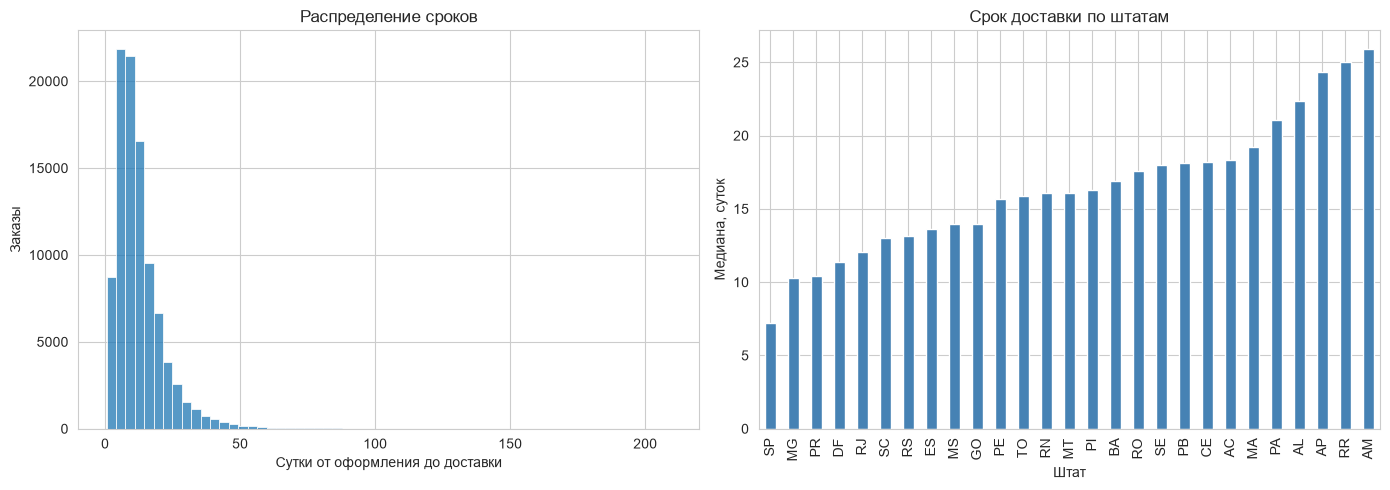

In [19]:
state_delivery = (delivered.loc[delivered['delivery_days'].ge(0)]
                  .groupby('customer_state').agg(orders=('order_id', 'nunique'),
                       median_days=('delivery_days', 'median'),
                       p90_days=('delivery_days', lambda s: s.quantile(0.9))))
display(state_delivery.sort_values('median_days', ascending=False).round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(delivered.loc[delivered['delivery_days'].ge(0), 'delivery_days'], bins=60, ax=axes[0])
axes[0].set(xlabel='Сутки от оформления до доставки', ylabel='Заказы', title='Распределение сроков')
state_delivery.sort_values('median_days')['median_days'].plot.bar(ax=axes[1], color='steelblue')
axes[1].set(xlabel='Штат', ylabel='Медиана, суток', title='Срок доставки по штатам')
plt.tight_layout()
plt.show()


Сроки доставки различаются по штатам. Для дальнейшего исследования стоит выбрать
направления с большим числом заказов и долгой доставкой, а затем посмотреть на
продавцов, расстояния и товарные категории.

Большинство заказов приходит вовремя относительно обещанной даты. Но сама по себе
доставка раньше обещания ещё не означает, что покупатель доволен её скоростью.
Для проверки этой связи нужны отзывы и сравнение повторных покупок у сопоставимых клиентов.

Здесь учитываем известные на момент выгрузки исходы заказов, оформленных до конца
августа. Часть из них доставлена позже. Статусы последних заказов могут ещё меняться.

### 2.4. Средний чек и структура заказов

Для каждого доставленного заказа сложим стоимость товарных позиций.
После этого посчитаем средний чек и долю заказов с одним товаром.


In [20]:
order_values = items.groupby('order_id').agg(order_value=('price', 'sum'), item_count=('order_item_id', 'count'))
delivered_values = delivered.merge(order_values, on='order_id', how='left', validate='one_to_one')
assert delivered_values['order_value'].notna().all()
average_order_value = delivered_values['order_value'].mean()
cancellation_share = events['order_status'].isin(['canceled', 'unavailable']).mean()


Средний чек доставленного заказа без доставки: **137.04 BRL**. Доля доставленных заказов с одной товарной позицией: **90.01%**. Доля отменённых/недоступных заказов среди всех оформлений: **1.22%**. Информации о возвратах полученных товаров в этих таблицах нет.


## Задача 3. Определить пять основных метрик

Выберем метрики, которые помогут следить за объёмом продаж, покупателями
и повторными заказами.

Для денежных показателей будем брать доставленные заказы и относить их к месяцу
оформления. Стоимость доставки в GMV не включаем.
Динамику покажем с января 2017 года: до этого в данных слишком мало заказов.


In [21]:
metric_months = pd.period_range(pd.Period('2017-01', freq='M'), end_month, freq='M')
monthly_metrics = delivered_values.groupby('order_month').agg(
    gmv=('order_value', 'sum'), buyers=('customer_unique_id', 'nunique'),
    orders=('order_id', 'nunique'))
monthly_metrics = monthly_metrics.reindex(metric_months)
assert monthly_metrics[['gmv', 'buyers', 'orders']].notna().all().all()
monthly_metrics['gmv_per_buyer'] = monthly_metrics['gmv'] / monthly_metrics['buyers']
monthly_metrics['average_order_value'] = monthly_metrics['gmv'] / monthly_metrics['orders']
assert np.allclose(monthly_metrics['gmv_per_buyer'] * monthly_metrics['buyers'], monthly_metrics['gmv'])
display(monthly_metrics.round(2))


,gmv,buyers,orders,gmv_per_buyer,average_order_value
2017-01,111798.36,718,750,155.71,149.06
2017-02,234223.40,1630,1653,143.70,141.70
2017-03,359198.85,2508,2546,143.22,141.08
2017-04,340669.68,2274,2303,149.81,147.92
2017-05,489338.25,3479,3546,140.65,138.00
2017-06,421923.37,3076,3135,137.17,134.58
2017-07,481604.52,3802,3872,126.67,124.38
2017-08,554699.70,4114,4193,134.83,132.29
2017-09,607399.67,4083,4150,148.76,146.36
2017-10,648247.65,4417,4478,146.76,144.76


### 3.1. Метрика роста объёма продаж — GMV

GMV — суммарная стоимость товаров в доставленных заказах за месяц.
Она показывает, как меняется объём продаж через маркетплейс.
Чтобы перейти от него к выручке самой площадки, нужны данные о комиссии и других доходах.

### 3.2. Объём аудитории, которой продукт доставляет ценность

Посчитаем уникальных покупателей, у которых за месяц есть хотя бы один заказ,
впоследствии доставленный. Несколько заказов одного человека учитываются один раз.

### 3.3. Заинтересованность новых клиентов — конверсия в первую покупку

Такую конверсию можно посчитать как долю новых посетителей, которые совершили первую
покупку за выбранное время после первого визита.

В наших данных есть только покупатели. Информации о посетителях, которые ничего
не заказали, нет, поэтому пока эту метрику рассчитать не можем.

### 3.4. Продолжение использования продукта — retention

Для этой задачи используем уже рассчитанный retention в оформление заказа.
Будем следить за M1 по новым когортам и за возвращениями на более длинных интервалах.

### 3.5. Денежное выражение активности — GMV на покупателя

Разделим месячный GMV на число уникальных покупателей доставленных заказов.
Так увидим, меняются ли расходы одного покупателя на товары.

Покажем динамику четырёх метрик, которые можем рассчитать по имеющимся данным.


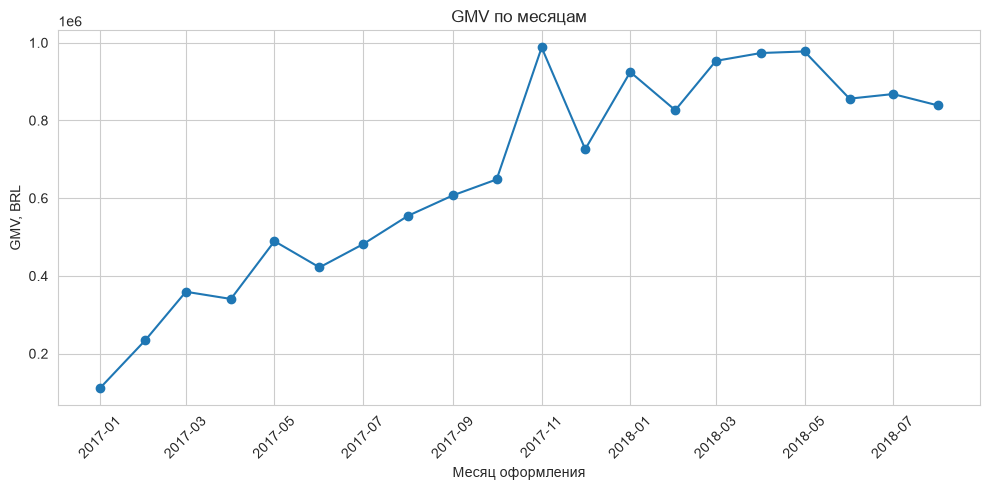

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_metrics.index.to_timestamp(), monthly_metrics['gmv'], marker='o')
plt.title('GMV по месяцам')
plt.xlabel('Месяц оформления')
plt.ylabel('GMV, BRL')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


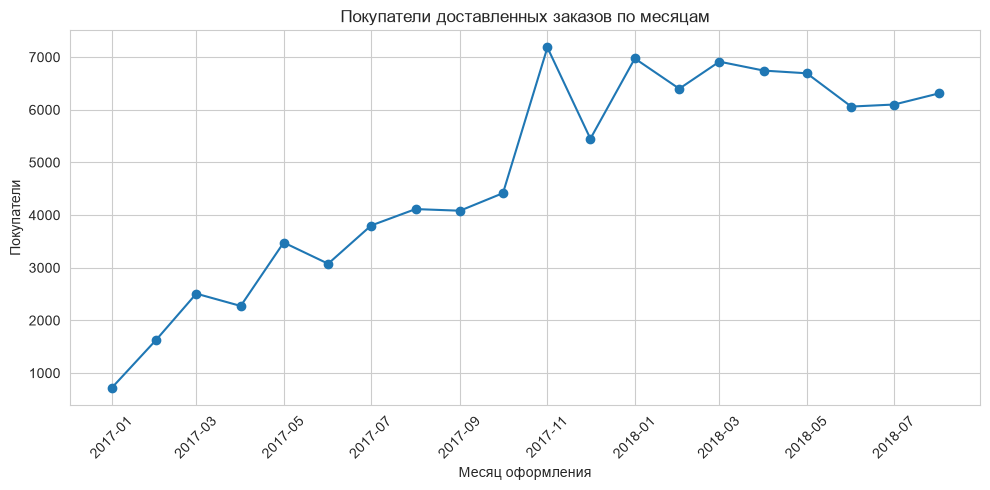

In [23]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_metrics.index.to_timestamp(), monthly_metrics['buyers'], marker='o')
plt.title('Покупатели доставленных заказов по месяцам')
plt.xlabel('Месяц оформления')
plt.ylabel('Покупатели')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


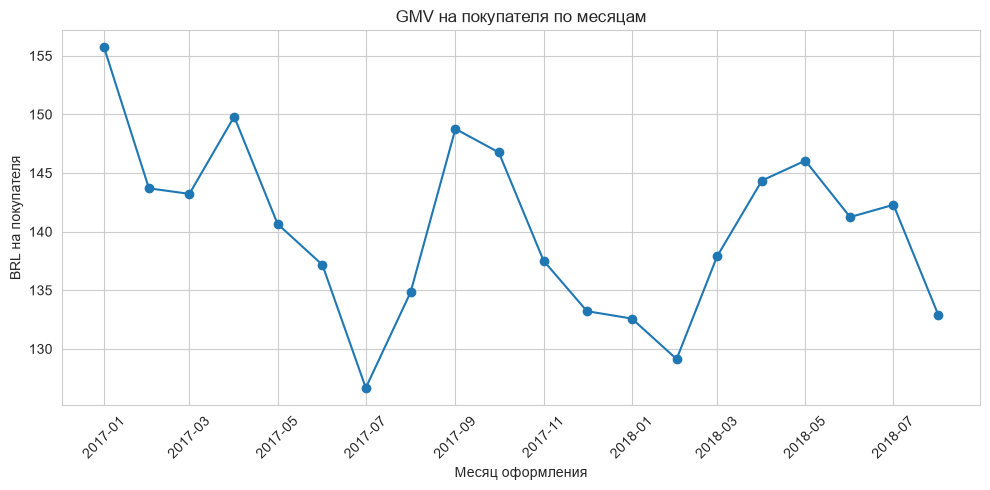

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_metrics.index.to_timestamp(), monthly_metrics['gmv_per_buyer'], marker='o')
plt.title('GMV на покупателя по месяцам')
plt.xlabel('Месяц оформления')
plt.ylabel('BRL на покупателя')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


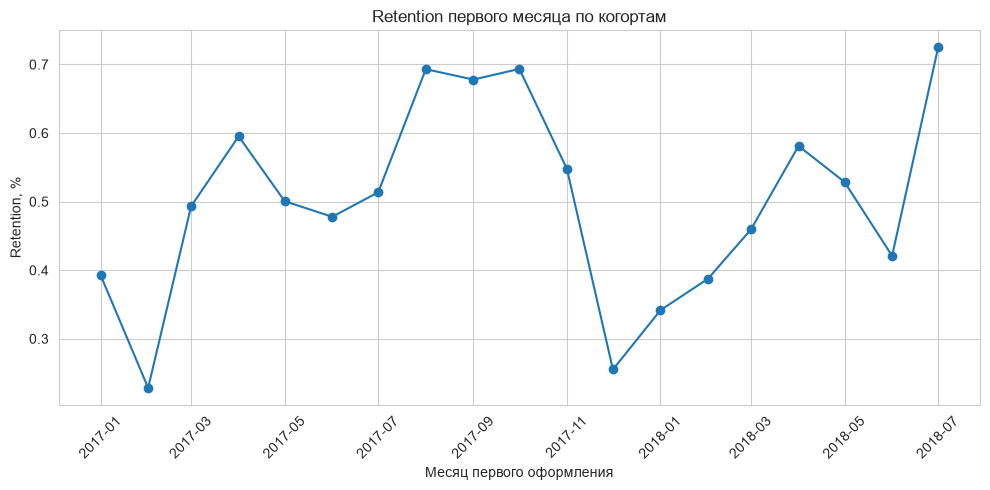

In [25]:
m1_series = retention.loc['2017-01':, 1]
plt.figure(figsize=(10, 5))
plt.plot(m1_series.index.to_timestamp(), m1_series * 100, marker='o')
plt.title('Retention первого месяца по когортам')
plt.xlabel('Месяц первого оформления')
plt.ylabel('Retention, %')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Дополнительно посмотрим, из кого складывается активная аудитория:
новые покупатели или пользователи, которые впервые заказывали в предыдущие месяцы.
Каждого человека учитываем один раз в месяц.


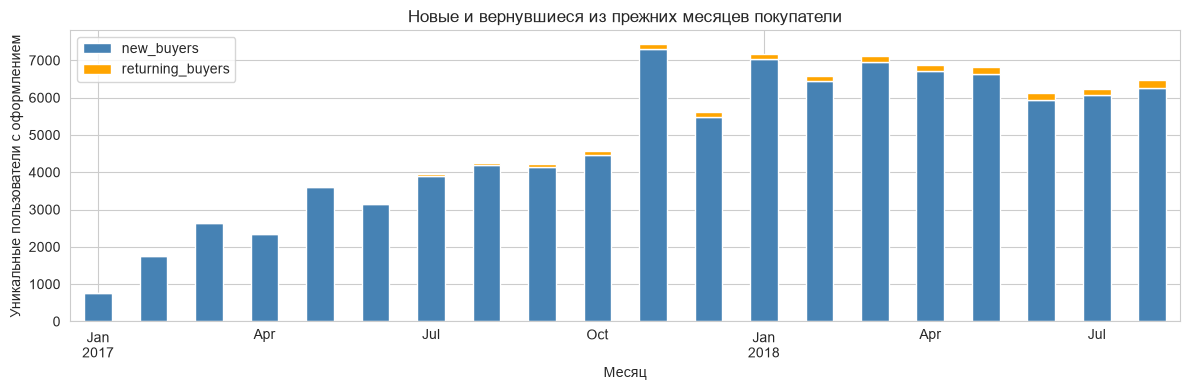

In [26]:
# Разделим покупателей на новых и вернувшихся из предыдущих месяцев.
first_month = events.groupby('customer_unique_id')['order_month'].min()
buyer_months = events[['customer_unique_id', 'order_month']].drop_duplicates()
buyer_months['returning'] = buyer_months['order_month'] > buyer_months['customer_unique_id'].map(first_month)
monthly_audience = buyer_months.groupby('order_month').agg(
    active_buyers=('customer_unique_id', 'nunique'), returning_buyers=('returning', 'sum'))
monthly_audience['new_buyers'] = monthly_audience['active_buyers'] - monthly_audience['returning_buyers']
monthly_audience['returning_share'] = monthly_audience['returning_buyers'] / monthly_audience['active_buyers']
assert monthly_audience['returning_share'].between(0, 1).all()
monthly_audience.loc[pd.Period('2017-01', freq='M'):, ['new_buyers', 'returning_buyers']].plot.bar(
    stacked=True, figsize=(12, 4), color=['steelblue', 'orange'])
plt.ylabel('Уникальные пользователи с оформлением')
plt.xlabel('Месяц')
plt.title('Новые и вернувшиеся из прежних месяцев покупатели')
plt.tight_layout()
plt.show()


In [27]:
peak_month = monthly_metrics['gmv'].idxmax()
latest = monthly_metrics.iloc[-1]


**Что видим по графикам:**

- Максимальный GMV за рассматриваемый период — в **2017-11**: **987,765.37 BRL**.
- В **2018-08** GMV составляет **838,576.64 BRL**, число покупателей доставленных заказов — **6,310**.
- GMV на покупателя за этот месяц — **132.90 BRL**.

В 2018 году уже нет такого последовательного роста объёма продаж, как в начале 2017-го. Чтобы понять причины, нужно отдельно изучить привлечение, повторные покупки и изменение товарного ассортимента.


## Задача 4. Выбрать гипотезу с помощью ICE

Есть три гипотезы: исправить процессинг заказов, сократить время до отгрузки
или добавить новый способ оплаты. Посчитаем возможное количество дополнительных
заказов и переведём его в Impact.

Для расчёта берём данные с **июня 2017 по август 2018 года**.
Конверсию в повторный заказ примем равной медианному M1 из первой задачи.
Confidence и Ease заданы заранее. Итоговый балл: **ICE = Impact × Confidence × Ease**.

Полученные значения — оценка при выбранных допущениях. Фактический прирост после
изменения нужно будет проверить в эксперименте.

### 4.1. Шкала Impact


In [28]:
# Шкала перевода дополнительных заказов в Impact.
impact_scale = pd.DataFrame({'Impact': range(1, 11),
    'Интервал числа заказов': ['0–50', '51–150', '151–350', '351–750', '751–1550',
        '1551–3150', '3151–6350', '6351–12750', '12751–25550', '25551–51150']})
display(impact_scale)


,Impact,Интервал числа заказов
0,1,0–50
1,2,51–150
2,3,151–350
3,4,351–750
4,5,751–1550
5,6,1551–3150
6,7,3151–6350
7,8,6351–12750
8,9,12751–25550
9,10,25551–51150


In [29]:
# Для гипотез берём заказы с июня 2017 года.
recent_orders = events.loc[events['order_month'] >= '2017-06'].copy()
print(f'Конверсия в повторный заказ: {median_m1:.4%}')


Конверсия в повторный заказ: 0.4969%


### 4.2. Гипотеза 1 — исправить процессинг заказов

Если исправим баг в системе процессинга, клиентам не придётся сталкиваться
с отменами и количество доставленных заказов увеличится.

Для этой оценки принимаем, что получится избежать **всех отмен**.
Посчитаем заказы со статусами `canceled` и `unavailable`: каждый из них в таком
сценарии станет дополнительным доставленным заказом.


In [30]:
# Заказы, которые могли бы быть доставлены, если избежать всех отмен.
canceled_orders = recent_orders.loc[
    recent_orders['order_status'].isin(['canceled', 'unavailable'])]
additional_orders_1 = canceled_orders['order_id'].nunique()

display(canceled_orders.groupby('order_status')['order_id'].nunique())
print('Дополнительные заказы:', additional_orders_1)


Дополнительные заказы: 955


order_status
canceled       480
unavailable    475
Name: order_id, dtype: int64

В данных нет причин всех отмен, поэтому до реализации нужно уточнить,
на какую их часть действительно влияет исправляемый баг.

### 4.3. Гипотеза 2 — сократить время до отгрузки

Если сократить время до отгрузки, клиенты будут реже получать заказы с опозданием
и могут чаще возвращаться за следующей покупкой.

Возьмём уникальных покупателей доставленных с опозданием заказов.
Умножим их число на принятую конверсию в повторный заказ.


In [31]:
# Считаем покупателей доставленных с опозданием заказов.
successful_orders = recent_orders.loc[recent_orders['order_status'] == 'delivered']
delayed_orders = successful_orders.loc[
    successful_orders['order_delivered_customer_date'].dt.normalize()
    > successful_orders['order_estimated_delivery_date'].dt.normalize()]
delayed_users = delayed_orders['customer_unique_id'].nunique()
additional_orders_2 = delayed_users * median_m1

print('Покупателей с опозданием:', delayed_users)
print('Дополнительные заказы:', round(additional_orders_2, 2))


Покупателей с опозданием: 6054
Дополнительные заказы: 30.08


### 4.4. Гипотеза 3 — добавить новый способ оплаты

Если новый способ оплаты упростит оформление, часть покупателей может вернуться
за повторным заказом.

Посмотрим на пользователей, у которых есть ровно один оформленный заказ за всю
доступную историю. Он должен быть доставлен и оформлен с июня 2017 года.
Более ранние заказы тоже проверяем: иначе покупатель с заказом до июня ошибочно
попадёт в группу тех, кто ещё не возвращался.


In [32]:
# Проверяем число оформлений за всю доступную историю, включая заказы до июня.
orders_per_user = events.groupby('customer_unique_id')['order_id'].nunique()
single_order_users = orders_per_user[orders_per_user == 1].index
single_buyers = successful_orders.loc[
    successful_orders['customer_unique_id'].isin(single_order_users),
    'customer_unique_id'].nunique()
additional_orders_3 = single_buyers * median_m1

print('Покупателей с единственным заказом:', single_buyers)
print('Дополнительные заказы:', round(additional_orders_3, 2))


Покупателей с единственным заказом: 80127
Дополнительные заказы: 398.12


В гипотезах 2 и 3 предполагаем, что выбранные покупатели сделают по одному
дополнительному заказу с вероятностью, равной M1. При этом срок наблюдения у них
разный, а причины отсутствия повторной покупки пока неизвестны.

### 4.5. Сравнение гипотез


In [33]:
ice = pd.DataFrame({
    'hypothesis': ['H1: процессинг', 'H2: отгрузка', 'H3: оплата'],
    'expected_orders': [additional_orders_1, additional_orders_2, additional_orders_3],
    'Confidence': [8, 10, 5],
    'Ease': [6, 4, 9],
}).set_index('hypothesis')

# Округляем ожидаемое число заказов и определяем интервал шкалы Impact.
ice['Impact'] = pd.cut(ice['expected_orders'].round(),
                       bins=[-1, 50, 150, 350, 750, 1550, 3150, 6350, 12750, 25550, 51150],
                       labels=range(1, 11)).astype(int)
ice['ICE'] = ice['Impact'] * ice['Confidence'] * ice['Ease']
display(ice)
winner = ice['ICE'].idxmax()
print('Наибольший приоритет:', winner)


Наибольший приоритет: H1: процессинг


,expected_orders,Confidence,Ease,Impact,ICE
hypothesis,,,,,
H1: процессинг,955.000000,8,6,5,240
H2: отгрузка,30.080136,10,4,1,40
H3: оплата,398.122075,5,9,4,180


Наибольший балл у первой гипотезы — **исправить процессинг заказов, ICE 240**. Предлагаю начать с проверки причин отмен, а затем проверить исправление в эксперименте.


## Задача 5. Метрики для проверки выбранной гипотезы

Выбрали исправление процессинга заказов. Теперь нужно понять, как проверить,
что изменение действительно помогает покупателям и бизнесу.

Предлагаю провести A/B-тест: случайно разделить пользователей на контроль и тест
до того, как они столкнутся с изменением. Один пользователь должен оставаться
в одной группе. Для обеих групп заранее зададим одинаковый период оформления
заказов и время ожидания их исходов.

### Целевая метрика

**Количество доставленных заказов на пользователя в эксперименте.**

Для каждой группы разделим число доставленных заказов, оформленных за выбранный
период, на число всех пользователей группы. Так увидим, увеличилось ли число
успешных покупок. Пользователи без заказов тоже остаются в знаменателе.

### Прокси-метрика

**Доля заказов с ошибкой процессинга.**

Если исправление работает, такая доля должна снижаться. Это можно увидеть раньше,
чем завершится доставка. Для расчёта понадобится журнал ошибок.

Дополнительно будем смотреть на долю `canceled` и `unavailable` и причины отмен.
Здесь важно отделить отмены из-за бага от остальных случаев.

### Guardrail-метрики

- **Конверсия в оформление:** пользователи с хотя бы одним заказом / все пользователи группы.
  Проверим, не стало ли сложнее оформить заказ.
- **Доля просроченных заказов:** доставленные позже обещания и ещё не доставленные
  после обещанного дня / заказы, у которых обещанный срок уже наступил.
  Проверим, справляется ли доставка с дополнительными заказами.
- **Обращения в поддержку на пользователя:** проверим, не возникли ли новые сложности
  на следующих этапах. Понадобятся данные поддержки.
- **Доля возвратов среди доставленных заказов с полным сроком наблюдения возврата:**
  проследим за качеством полученного результата. Для неё тоже нужны дополнительные данные.

До запуска определим минимальный интересующий нас эффект, размер выборки,
длительность теста и допустимое ухудшение guardrail-метрик.
При оценке результатов учтём, что у одного пользователя может быть несколько заказов.


## Задача 6. Итоги исследования

Соберём основные результаты и определим, с чего стоит начать работу над продуктом.


# Анализ причин отсутствия роста выручки маркетплейса

Несколько месяцев выручка маркетплейса не растёт. Мы исследовали заказы,
покупателей и товарные позиции, чтобы найти возможные точки роста и выбрать
гипотезу для проверки. По доступным данным можно оценить объём продаж товаров —
GMV. Для расчёта выручки и прибыли самой площадки нужны комиссия и расходы.

## 1. Возвращение покупателей

Медианный retention первого месяца составляет **0.497%**:
в следующий календарный месяц возвращается небольшая доля покупателей.
Считаем все оформления, включая заказы, которые позже отменили.

Лучший retention на третий месяц у когорты **2017-06 — 0.414%**.
Это **13** вернувшихся из **3139** покупателей.

У **96.89%** пользователей за доступный период только одно оформление.
При этом у новых покупателей было меньше времени на следующую покупку.
Если взять 14 когорт с полным наблюдением M1–M6, медианная доля
вернувшихся хотя бы раз за эти месяцы составляет **1.79%**.

Повторные покупки — возможная точка роста. Но чтобы оценить PMF увереннее,
нужно понимать категории товаров и то, как часто покупатели обычно в них возвращаются.
Устойчивый PMF по имеющимся данным подтвердить не можем.

## 2. Объём продаж и средний чек

Максимальный GMV за рассматриваемый период был в **2017-11** и составил
**987,765.37 BRL**.
В **2018-08** объём продаж — **838,576.64 BRL**, покупателей
доставленных заказов — **6,310**, GMV на покупателя — **132.90 BRL**.

Средний чек доставленного заказа за основной период — **137.04 BRL**
без стоимости доставки. Чтобы его посчитать, сначала складывали стоимость
всех товарных позиций каждого заказа.

В 2018 году объём продаж уже не показывает последовательного роста, который
наблюдался в начале 2017-го. Для поиска причин стоит отдельно изучить
привлечение новых покупателей, повторные покупки и ассортимент.

## 3. Доставка и отмены

Медианное время от оформления до доставки составляет **10.22 суток**.
Среди доставленных заказов с известными датами **6.77%** пришли
позже обещанного дня. Сроки отличаются по штатам — это повод подробнее
посмотреть на отдельные направления доставки.

Доля заказов со статусами canceled и unavailable — **1.22%**.
Информации о возвратах уже полученных товаров в таблицах нет.

## 4. Какую гипотезу проверять первой

Для сравнения использовали ICE и конверсию в повторный заказ **0.4969%**.
Получились следующие оценки:

- **H1: процессинг**: около 955 дополнительных заказов; Impact 5, Confidence 8, Ease 6; **ICE 240**.
- **H2: отгрузка**: около 30 дополнительных заказов; Impact 1, Confidence 10, Ease 4; **ICE 40**.
- **H3: оплата**: около 398 дополнительных заказов; Impact 4, Confidence 5, Ease 9; **ICE 180**.


Наибольший приоритет у **первой гипотезы — исправить процессинг заказов**.
В расчёте принимали, что исправление позволит избежать всех отмен.
Перед реализацией нужно проверить причины отмен и оценить, какая их часть
действительно связана с багом. Эффект стоит проверить в A/B-тесте.

## 5. Что делать дальше

1. Разобраться с причинами отмен и проверить гипотезу об исправлении процессинга.
2. В эксперименте следить за доставленными заказами на пользователя,
   ошибками процессинга, конверсией в оформление, просрочками и обращениями в поддержку.
3. Изучить повторные покупки по категориям товаров и собрать обратную связь
   после первого заказа. Это поможет выбрать подходящие механики удержания.
4. Проверить направления с долгой доставкой и большим числом заказов.
5. Добавить данные о комиссии и расходах, чтобы оценивать изменения по их влиянию на прибыль.

## Период и особенности расчёта

Основные расчёты заканчиваются августом 2018 года. За сентябрь и октябрь есть
только единичные записи, поэтому полноту конца выгрузки нужно уточнить.
В расчёте август считаем полным месяцем.
Историю 2016 года сохранили для определения первого наблюдаемого заказа.

Retention считается по календарным месяцам. Если никто не вернулся в уже
прошедшем месяце, ставим 0; если месяц ещё не наблюдался — оставляем пропуск.
GMV считается по доставленным заказам в месяце оформления, без стоимости доставки.
Причины поведения покупателей и фактический эффект изменений требуют дальнейшей проверки.
